In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Load
scores = pd.read_csv("results_extended/author_scores_delta05.csv")
multi = scores[scores["n_papers"] >= 2].copy()

extended = pd.read_csv("adapted_extended_cohort.csv")
seed_map = extended.groupby("author_anon_id")["seed_author_anon_id"].agg(
    lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else None
)
multi_with_seed = multi.merge(
    seed_map.rename("seed"), left_on="author_anon_id", right_index=True, how="left"
)

# Seed name lookup for prettier labels
seeds_meta = pd.read_csv("seed_authors_for_matching.csv")
seed_name_lookup = dict(zip(seeds_meta["openalex_id"], seeds_meta["first_name"] + " " + seeds_meta["last_name"]))

# Correlation check (mentioned in earlier discussion)
print("Correlation matrix (multi-paper authors):")
print(multi[["delta_country", "delta_discipline", "beta_mean"]].corr().round(3))

Correlation matrix (multi-paper authors):
                  delta_country  delta_discipline  beta_mean
delta_country             1.000            -0.030      0.057
delta_discipline         -0.030             1.000      0.202
beta_mean                 0.057             0.202      1.000


In [3]:
# Base scatter: all multi-paper authors
fig = px.scatter(
    multi_with_seed,
    x="delta_country",
    y="delta_discipline",
    hover_data=["author_anon_id", "n_papers", "beta_mean"],
    opacity=0.3,
    title="Country vs discipline diversity — multi-paper authors (extended cohort)",
    labels={
        "delta_country": "δ_country (income-group diversity)",
        "delta_discipline": "δ_discipline (topic diversity)",
    },
)

# Overlay seeds as bigger, differently-colored points with labels
seed_ids = list(seed_name_lookup.keys())
seed_rows = multi[multi.index.isin(seed_ids) | multi["author_anon_id"].isin(seed_ids)].copy()

# Handle whichever column has the ID
if "author_anon_id" in seed_rows.columns:
    seed_rows["seed_name"] = seed_rows["author_anon_id"].map(seed_name_lookup)
else:
    seed_rows["seed_name"] = seed_rows.index.map(seed_name_lookup)

fig.add_trace(go.Scatter(
    x=seed_rows["delta_country"],
    y=seed_rows["delta_discipline"],
    mode="markers+text",
    marker=dict(size=14, color="red", line=dict(width=2, color="black")),
    text=seed_rows["seed_name"],
    textposition="top right",
    textfont=dict(size=10),
    name="Seed authors",
    hovertext=seed_rows["seed_name"] + " (n=" + seed_rows["n_papers"].astype(str) + ")",
    hoverinfo="text",
))

fig.update_layout(width=900, height=600)
fig.show()

In [4]:
seed_name_lookup = dict(zip(seeds_meta["author_anon_id"], 
                             seeds_meta["first_name"] + " " + seeds_meta["last_name"]))
multi_with_seed["seed_name"] = multi_with_seed["seed"].map(seed_name_lookup)

In [5]:
# One histogram per seed showing their co-authors' country diversity
multi_with_seed["seed_name"] = multi_with_seed["seed"].map(seed_name_lookup)

fig = px.histogram(
    multi_with_seed.dropna(subset=["seed_name"]),
    x="delta_country",
    facet_col="seed_name",
    facet_col_wrap=5,  # 5 per row = 2 rows of 5
    nbins=20,
    title="Country diversity distribution by seed author's network",
    labels={"delta_country": "δ_country", "count": "Number of co-authors"},
)

# Clean up facet titles (remove "seed_name=" prefix)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))

# Set consistent x-axis range so distributions are visually comparable
fig.update_xaxes(range=[0, 0.5])

fig.update_layout(width=1400, height=500, showlegend=False)
fig.show()

In [6]:
paper_scores = pd.read_csv("results_extended/paper_scores.csv", index_col="pub_anon_id")
extended = pd.read_csv("adapted_extended_cohort.csv")

extended_with_scores = extended.merge(
    paper_scores[["delta_country"]],
    left_on="pub_anon_id",
    right_index=True,
    how="left"
)

seed_name_lookup_anon = dict(zip(
    seeds_meta["author_anon_id"],
    seeds_meta["first_name"] + " " + seeds_meta["last_name"]
))

fig = px.histogram(
    extended_with_scores.dropna(subset=["seed_author_anon_id"]),
    x="delta_country",
    facet_col="seed_author_anon_id",
    facet_col_wrap=5,
    nbins=20,
    histnorm="percent",
    title="Paper-level country diversity across each seed's publications",
)
fig.for_each_annotation(lambda a: a.update(
    text=seed_name_lookup_anon.get(a.text.split("=")[-1], a.text.split("=")[-1])
))
fig.update_xaxes(range=[0, 0.5])
fig.update_layout(width=1400, height=500, showlegend=False)
fig.show()

In [7]:
sensitivity = pd.read_csv("results_extended/sensitivity_delta.csv")

# For extended cohort, scalar is 0 (gender-forced-zero), so use component-based ranking
# Actually the more direct claim: how much do β̄ contributions shift author-level scores?
scores_d0 = pd.read_csv("results_extended/author_scores_delta0.csv")
scores_d1 = pd.read_csv("results_extended/author_scores_delta1.csv")

# Compare a summary score (e.g., mean of country + discipline) across delta values
def summary(row):
    return (row["delta_country"] + row["delta_discipline"]) / 2

scores_d0["score"] = scores_d0.apply(summary, axis=1)
scores_d1["score"] = scores_d1.apply(summary, axis=1)

joined = scores_d0[["score"]].join(scores_d1[["score"]], rsuffix="_d1")
joined = joined[joined.index.isin(scores_d0[scores_d0["n_papers"] >= 2].index)]
print(f"Spearman rank correlation δ=0 vs δ=1: {joined['score'].corr(joined['score_d1'], method='spearman'):.3f}")

Spearman rank correlation δ=0 vs δ=1: 0.964


In [8]:
paper_field_series = (extended.groupby("pub_anon_id")["specialization"]
    .first()
    .dropna()
    .str.split("||", regex=False)
    .apply(lambda parts: parts[1] if len(parts) >= 2 else None)
)

merged = paper_scores.join(paper_field_series.rename("field"))
by_field = merged.dropna(subset=["field"]).groupby("field").agg(
    n_papers=("delta_country", "count"),
    mean_country=("delta_country", "mean"),
    pct_zero=("delta_country", lambda x: (x == 0).mean() * 100),
).sort_values("mean_country", ascending=False)

print(by_field[by_field["n_papers"] >= 20].round(3))

                                              n_papers  mean_country  pct_zero
field                                                                         
Chemistry                                          184         0.115    41.304
Energy                                             777         0.051    59.974
Materials Science                                  221         0.049    59.729
Biochemistry, Genetics and Molecular Biology        57         0.035    71.930
Engineering                                        385         0.031    71.169
Computer Science                                    26         0.031    76.923
Environmental Science                              167         0.030    75.449
Medicine                                           429         0.024    76.224
Physics and Astronomy                               20         0.023    75.000


In [9]:
by_field_disc = merged.dropna(subset=["field"]).groupby("field").agg(
    n_papers=("delta_discipline", "count"),
    mean_disc=("delta_discipline", "mean"),
    pct_zero=("delta_discipline", lambda x: (x == 0).mean() * 100),
).sort_values("mean_disc", ascending=False)

print(by_field_disc[by_field_disc["n_papers"] >= 20].round(3))

                                              n_papers  mean_disc  pct_zero
field                                                                      
Biochemistry, Genetics and Molecular Biology        57      0.495     1.754
Physics and Astronomy                               20      0.369     0.000
Computer Science                                    26      0.350     3.846
Chemistry                                          184      0.315     0.000
Environmental Science                              167      0.314     1.198
Engineering                                        385      0.311     1.299
Materials Science                                  221      0.308     0.000
Medicine                                           429      0.215    17.016
Energy                                             777      0.172    35.393


In [10]:
# What fraction of Chemistry papers come from each seed's network?
chemistry_papers = merged[merged["field"] == "Chemistry"].index
extended_chem = extended[extended["pub_anon_id"].isin(chemistry_papers)]
print("Chemistry papers by seed:")
print(extended_chem.groupby("seed_author_anon_id")["pub_anon_id"].nunique().sort_values(ascending=False))

Chemistry papers by seed:
seed_author_anon_id
A38327606686f    149
Ab1e8b19bae0b     11
Aa6270b01971b      9
Af103ef0d80ce      8
A6e2aff8d4f11      4
A11460d5aa670      1
A77c21dacbd16      1
Afb5914645166      1
Name: pub_anon_id, dtype: int64


In [11]:
import json
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Load h-index data
with open("author_topics.json") as f:
    author_topics = json.load(f)

h_index_lookup = {aid: v["h_index"] for aid, v in author_topics.items() if v and v.get("h_index") is not None}
print(f"H-index available for {len(h_index_lookup):,} authors")

# Load scores and merge
scores = pd.read_csv("results_extended/author_scores_delta05.csv")
scores["h_index"] = scores["author_anon_id"].map(h_index_lookup) if "author_anon_id" in scores.columns else scores.index.map(h_index_lookup)
multi = scores[scores["n_papers"] >= 2].copy()
multi = multi.dropna(subset=["h_index"])
print(f"Multi-paper authors with h-index: {len(multi):,}")

# Seed lookup
seeds_meta = pd.read_csv("seed_authors_for_matching.csv")
seed_name_lookup = dict(zip(seeds_meta["openalex_id"], seeds_meta["first_name"] + " " + seeds_meta["last_name"]))

H-index available for 5,750 authors
Multi-paper authors with h-index: 1,684


In [12]:
from plotly.subplots import make_subplots

fig = make_subplots(rows=1, cols=3, subplot_titles=("δ_country vs h-index", "δ_discipline vs h-index", "β̄ vs h-index"))

for i, col in enumerate(["delta_country", "delta_discipline", "beta_mean"]):
    fig.add_trace(go.Scatter(
        x=multi["h_index"],
        y=multi[col],
        mode="markers",
        marker=dict(size=4, opacity=0.3, color="steelblue"),
        name=col,
        showlegend=False,
    ), row=1, col=i+1)
    
    # Overlay seeds
    seed_rows = multi[multi.index.astype(str).isin(seed_name_lookup) | 
                       (multi["author_anon_id"].isin(seed_name_lookup) if "author_anon_id" in multi.columns else False)]
    if len(seed_rows):
        fig.add_trace(go.Scatter(
            x=seed_rows["h_index"],
            y=seed_rows[col],
            mode="markers",
            marker=dict(size=10, color="red", line=dict(width=1.5, color="black")),
            showlegend=(i == 0),
            name="Seed authors",
        ), row=1, col=i+1)
    
    # Add correlation coefficient
    corr = multi[["h_index", col]].corr(method="spearman").iloc[0, 1]
    fig.add_annotation(text=f"Spearman ρ = {corr:.2f}", 
                        xref=f"x{i+1}" if i > 0 else "x", yref="paper",
                        x=multi["h_index"].max() * 0.7, y=0.98,
                        showarrow=False, font=dict(size=11), row=1, col=i+1)

fig.update_xaxes(title_text="h-index (OpenAlex)")
fig.update_yaxes(title_text="Score", row=1, col=1)
fig.update_layout(width=1400, height=450, title="Comm-index components vs h-index — extended cohort")
fig.show()

# Print correlations
print("\nSpearman correlations with h-index:")
for col in ["delta_country", "delta_discipline", "beta_mean", "n_papers"]:
    corr = multi[["h_index", col]].corr(method="spearman").iloc[0, 1]
    print(f"  {col}: {corr:.3f}")


Spearman correlations with h-index:
  delta_country: 0.224
  delta_discipline: -0.169
  beta_mean: -0.093
  n_papers: 0.199


In [13]:
import numpy as np

# 2D composite for extended cohort
multi["composite_2d"] = np.sqrt(multi["delta_country"] * multi["delta_discipline"])

fig = px.scatter(
    multi,
    x="h_index",
    y="composite_2d",
    hover_data=(["author_anon_id"] if "author_anon_id" in multi.columns else None),
    opacity=0.3,
    title="h-index vs 2D comm-index composite (√(δ_country × δ_discipline)) — extended cohort",
    labels={"h_index": "h-index (OpenAlex)", "composite_2d": "Comm-index composite (2D)"},
)

# Overlay seeds
id_col = "author_anon_id" if "author_anon_id" in multi.columns else None
if id_col:
    seed_rows = multi[multi[id_col].isin(seed_name_lookup)].copy()
    seed_rows["seed_name"] = seed_rows[id_col].map(seed_name_lookup)
else:
    seed_rows = multi[multi.index.astype(str).isin(seed_name_lookup)].copy()
    seed_rows["seed_name"] = seed_rows.index.map(seed_name_lookup)

fig.add_trace(go.Scatter(
    x=seed_rows["h_index"],
    y=seed_rows["composite_2d"],
    mode="markers+text",
    marker=dict(size=14, color="red", line=dict(width=2, color="black")),
    text=seed_rows["seed_name"],
    textposition="top right",
    textfont=dict(size=9),
    name="Seed authors",
))

# Correlation
corr = multi[["h_index", "composite_2d"]].corr(method="spearman").iloc[0, 1]
fig.add_annotation(text=f"Spearman ρ = {corr:.2f}", 
                    xref="paper", yref="paper",
                    x=0.75, y=0.98, showarrow=False, font=dict(size=12))

fig.update_layout(width=1000, height=600)
fig.show()

In [14]:
import matplotlib as mpl 
import matplotlib.pyplot as plt 
import seaborn as sns 

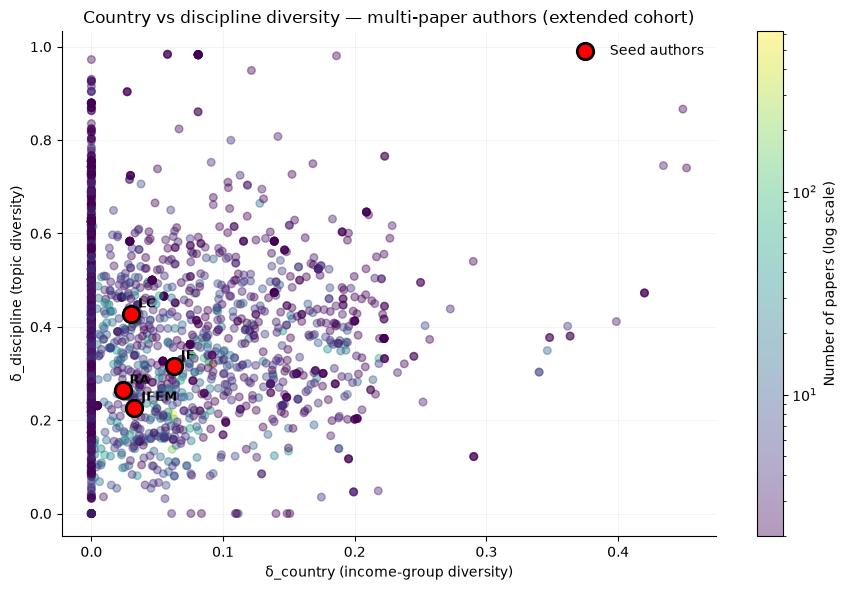

In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# --------------------------------
# Convert seed names -> initials
# --------------------------------
seed_initials_lookup = {
    author_id: "".join(
        part[0].upper()
        for part in name.split()
        if part
    )
    for author_id, name in seed_name_lookup.items()
}

# --------------------------------
# Base scatter
# --------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

scatter = ax.scatter(
    multi_with_seed["delta_country"],
    multi_with_seed["delta_discipline"],
    c=multi_with_seed["n_papers"],
    cmap="viridis",
    norm=LogNorm(
        vmin=multi_with_seed["n_papers"].min(),
        vmax=multi_with_seed["n_papers"].max()
    ),
    alpha=0.4,
    s=30
)

# Colorbar
cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Number of papers (log scale)")

# --------------------------------
# Find seed authors
# --------------------------------
seed_ids = list(seed_name_lookup.keys())

seed_rows = multi[
    multi.index.isin(seed_ids) |
    multi["author_anon_id"].isin(seed_ids)
].copy()

# --------------------------------
# Highlight seed authors
# --------------------------------
ax.scatter(
    seed_rows["delta_country"],
    seed_rows["delta_discipline"],
    s=140,
    c="red",
    edgecolors="black",
    linewidths=2,
    zorder=3,
    label="Seed authors"
)

# --------------------------------
# Label seed authors with initials
# --------------------------------
for idx, row in seed_rows.iterrows():

    if row["author_anon_id"] in seed_initials_lookup:
        author_id = row["author_anon_id"]
    elif idx in seed_initials_lookup:
        author_id = idx
    else:
        continue

    ax.annotate(
        seed_initials_lookup[author_id],
        (row["delta_country"], row["delta_discipline"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

# --------------------------------
# Labels
# --------------------------------
ax.set_xlabel(
    "δ_country (income-group diversity)"
)

ax.set_ylabel(
    "δ_discipline (topic diversity)"
)

ax.set_title(
    "Country vs discipline diversity — "
    "multi-paper authors (extended cohort)"
)

# Cleaner publication-style formatting
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    alpha=0.15,
    linewidth=0.7
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False
)

fig.tight_layout()
plt.show()

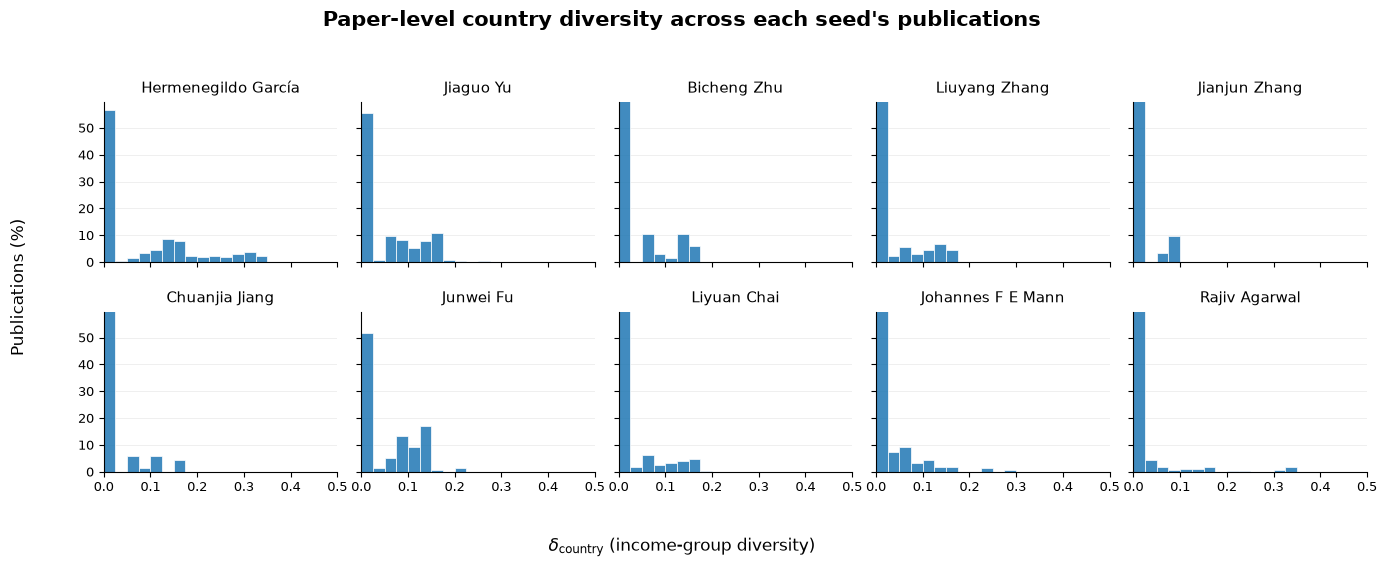

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Load and merge data
# -----------------------------
paper_scores = pd.read_csv(
    "results_extended/paper_scores.csv",
    index_col="pub_anon_id"
)

extended = pd.read_csv("adapted_extended_cohort.csv")

extended_with_scores = extended.merge(
    paper_scores[["delta_country"]],
    left_on="pub_anon_id",
    right_index=True,
    how="left"
)

# Seed author name lookup
seed_name_lookup_anon = dict(
    zip(
        seeds_meta["author_anon_id"],
        seeds_meta["first_name"] + " " + seeds_meta["last_name"]
    )
)

# Keep only papers with a seed author and valid delta_country
plot_data = extended_with_scores.dropna(
    subset=["seed_author_anon_id", "delta_country"]
).copy()
plot_data_dedup = plot_data[["seed_author_anon_id", "pub_anon_id", "delta_country"]].drop_duplicates(
    subset=["seed_author_anon_id", "pub_anon_id"]
)
# -----------------------------
# Set up facets
# -----------------------------
seed_ids = plot_data["seed_author_anon_id"].unique()

n_cols = 5
n_rows = int(np.ceil(len(seed_ids) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 2.8 * n_rows),
    sharex=True,
    sharey=True
)

# Make axes iterable even if there's only one row
axes = np.atleast_1d(axes).flatten()

# Common bins across every subplot
bins = np.linspace(0, 0.5, 21)

# -----------------------------
# Plot each seed
# -----------------------------
for ax, seed_id in zip(axes, seed_ids):

    values = plot_data_dedup.loc[
        plot_data["seed_author_anon_id"] == seed_id,
        "delta_country"
    ]

    # Convert histogram counts to percentages
    weights = np.ones(len(values)) * 100 / len(values)

    ax.hist(
        values,
        bins=bins,
        weights=weights,
        edgecolor="white",
        linewidth=0.6,
        alpha=0.85
    )

    # Seed name
    name = seed_name_lookup_anon.get(
        seed_id,
        str(seed_id)
    )

    ax.set_title(
        name,
        fontsize=11,
        fontweight="medium",
        pad=7
    )

    ax.set_xlim(0, 0.5)
    ax.set_ylim(bottom=0)

    # Clean up spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Light horizontal grid
    ax.grid(
        axis="y",
        alpha=0.2,
        linewidth=0.7
    )

    ax.set_axisbelow(True)

# -----------------------------
# Remove unused panels
# -----------------------------
for ax in axes[len(seed_ids):]:
    ax.remove()

# -----------------------------
# Shared labels
# -----------------------------
fig.supxlabel(
    r"$\delta_{\mathrm{country}}$ (income-group diversity)",
    fontsize=12,
    y=0.02
)

fig.supylabel(
    "Publications (%)",
    fontsize=12,
    x=0.02
)

fig.suptitle(
    "Paper-level country diversity across each seed's publications",
    fontsize=15,
    fontweight="bold",
    y=0.995
)

# Consistent tick sizes
for ax in axes[:len(seed_ids)]:
    ax.tick_params(
        axis="both",
        labelsize=9
    )

fig.tight_layout(
    rect=[0.035, 0.045, 1, 0.96],
    h_pad=1.5,
    w_pad=1.0
)

plt.show()

In [21]:
paper_level = (
    plot_data[["seed_author_anon_id", "pub_anon_id", "delta_country"]]
    .drop_duplicates(subset=["seed_author_anon_id", "pub_anon_id"])
)

paper_zero_rates = (
    paper_level.groupby("seed_author_anon_id")["delta_country"]
    .apply(lambda x: (x == 0).mean() * 100)
    .sort_values(ascending=False)
)

for seed_id, rate in paper_zero_rates.items():
    name = seed_name_lookup_anon.get(seed_id, str(seed_id))
    n_papers = paper_level[paper_level["seed_author_anon_id"] == seed_id]["pub_anon_id"].nunique()
    print(f"  {name}: {rate:.1f}% zero-country ({n_papers} papers)")

  Jianjun Zhang: 87.1% zero-country (31 papers)
  Rajiv Agarwal: 85.9% zero-country (249 papers)
  Chuanjia Jiang: 82.1% zero-country (67 papers)
  Liyuan Chai: 76.8% zero-country (328 papers)
  Liuyang Zhang: 73.0% zero-country (174 papers)
  Bicheng Zhu: 68.2% zero-country (66 papers)
  Johannes F E Mann: 65.6% zero-country (160 papers)
  Hermenegildo García: 55.9% zero-country (494 papers)
  Jiaguo Yu: 55.7% zero-country (609 papers)
  Junwei Fu: 51.8% zero-country (141 papers)


In [22]:
scores = pd.read_csv("results_extended/author_scores_delta05.csv")
multi = scores[scores["n_papers"] >= 2]
zero_rate = (multi["delta_country"] == 0).mean() * 100
print(f"Multi-paper authors with mean δ_country = 0: {zero_rate:.1f}% (n={len(multi)})")

Multi-paper authors with mean δ_country = 0: 41.8% (n=2033)


In [17]:
import numpy as np
from scipy import stats

def spearman_with_ci(x, y, alpha=0.05):
    """Return (rho, ci_low, ci_high, n) using Fisher z-transformation."""
    valid = ~(np.isnan(x) | np.isnan(y))
    x, y = x[valid], y[valid]
    n = len(x)
    rho, _ = stats.spearmanr(x, y)
    # Fisher z transform
    z = np.arctanh(rho)
    se = 1.0 / np.sqrt(n - 3)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    ci_low = np.tanh(z - z_crit * se)
    ci_high = np.tanh(z + z_crit * se)
    return rho, ci_low, ci_high, n

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.


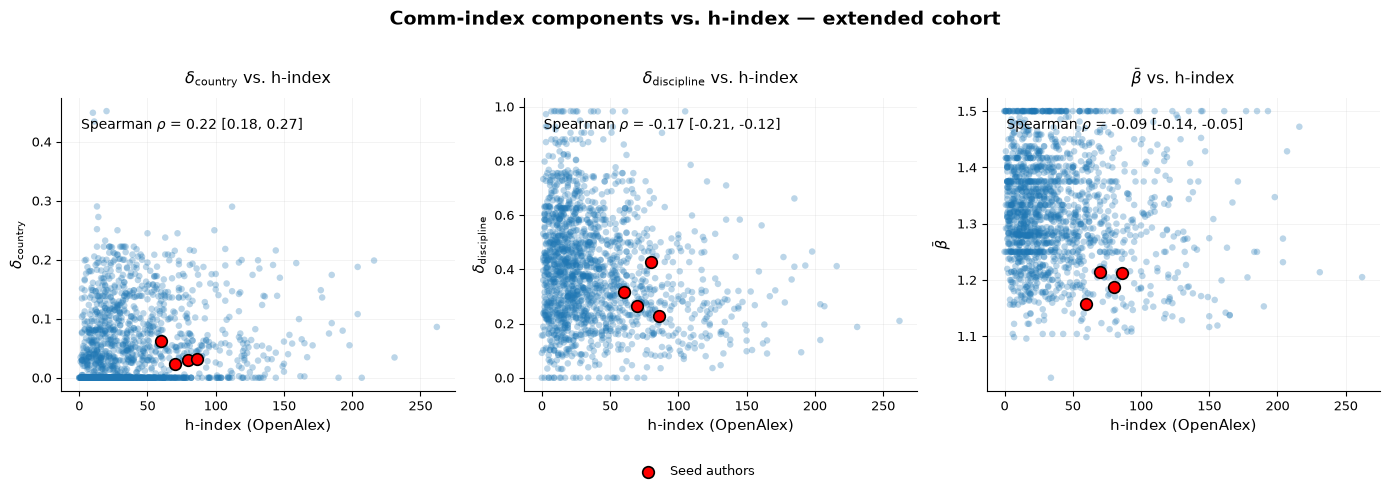


Spearman correlations with h-index:
  delta_country: 0.224
  delta_discipline: -0.169
  beta_mean: -0.093
  n_papers: 0.199


In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Variables to plot
cols = [
    "delta_country",
    "delta_discipline",
    "beta_mean"
]

y_labels = [
    r"$\delta_{\mathrm{country}}$",
    r"$\delta_{\mathrm{discipline}}$",
    r"$\bar{\beta}$"
]

titles = [
    r"$\delta_{\mathrm{country}}$ vs. h-index",
    r"$\delta_{\mathrm{discipline}}$ vs. h-index",
    r"$\bar{\beta}$ vs. h-index"
]

# --------------------------------
# Identify seed authors
# --------------------------------
seed_ids = list(seed_name_lookup.keys())

seed_rows = multi[
    multi.index.isin(seed_ids) |
    multi["author_anon_id"].isin(seed_ids)
].copy()

# --------------------------------
# Create figure
# --------------------------------
fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4.3),
    sharex=True
)

for ax, col, ylabel, title in zip(
    axes,
    cols,
    y_labels,
    titles
):

    # Remove missing values for correlation + plotting
    plot_data = multi[["h_index", col]].dropna()

    # --------------------------------
    # Background authors
    # --------------------------------
    ax.scatter(
        plot_data["h_index"],
        plot_data[col],
        s=22,
        alpha=0.3,
        edgecolors="none"
    )

    # --------------------------------
    # Seed authors
    # --------------------------------
    seed_plot = seed_rows[["h_index", col]].dropna()

    if len(seed_plot):
        ax.scatter(
            seed_plot["h_index"],
            seed_plot[col],
            s=70,
            c="red",
            edgecolors="black",
            linewidths=1.2,
            zorder=3,
            label="Seed authors"
        )




    '''
    # --------------------------------
    # Spearman correlation
    # --------------------------------
    corr = plot_data.corr(method="spearman").iloc[0, 1]

    ax.text(
        0.05,
        0.93,
        rf"Spearman $\rho$ = {corr:.2f}",
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="top"
    )

    ''' 
    # --------------------------------
    # Spearman correlation with 95% CI
    # --------------------------------
    rho, ci_low, ci_high, n = spearman_with_ci(
        plot_data["h_index"].values,
        plot_data[col].values
    )

    ax.text(
        0.05,
        0.93,
        rf"Spearman $\rho$ = {rho:.2f} [{ci_low:.2f}, {ci_high:.2f}]",
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="top"
    )
    # --------------------------------
    # Formatting
    # --------------------------------
    ax.set_title(
        title,
        fontsize=11.5,
        fontweight="medium",
        pad=10
    )

    ax.set_xlabel(
        "h-index (OpenAlex)",
        fontsize=10.5
    )

    ax.set_ylabel(
        ylabel,
        fontsize=10.5
    )

    ax.tick_params(
        axis="both",
        labelsize=9
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        alpha=0.15,
        linewidth=0.7
    )

    ax.set_axisbelow(True)

# --------------------------------
# Single legend
# --------------------------------
handles, labels = axes[0].get_legend_handles_labels()

if handles:
    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.01),
        frameon=False,
        fontsize=9
    )

# --------------------------------
# Overall title
# --------------------------------
fig.suptitle(
    "Comm-index components vs. h-index — extended cohort",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

fig.tight_layout()

plt.show()


# --------------------------------
# Print correlations
# --------------------------------
print("\nSpearman correlations with h-index:")

for col in ["delta_country", "delta_discipline", "beta_mean", "n_papers"]:
    corr = multi[["h_index", col]].corr(method="spearman").iloc[0, 1]
    print(f"  {col}: {corr:.3f}")

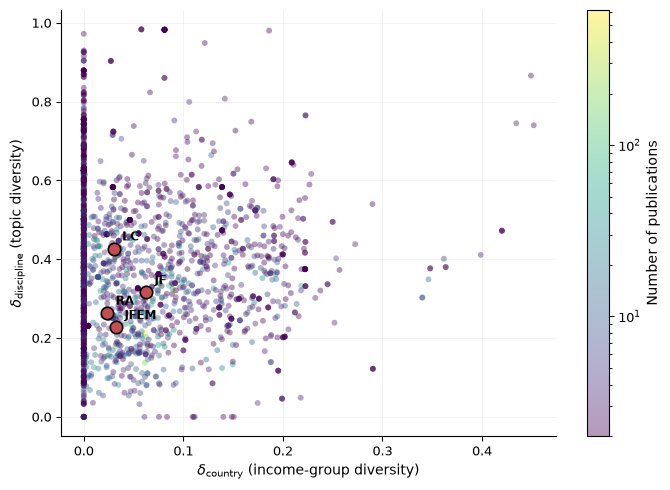

In [24]:
### Visualizations for publication
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# --------------------------------
# Convert seed names -> initials
# --------------------------------
seed_initials_lookup = {
    author_id: "".join(
        part[0].upper()
        for part in name.split()
        if part
    )
    for author_id, name in seed_name_lookup.items()
}

# --------------------------------
# Base scatter
# --------------------------------
fig, ax = plt.subplots(figsize=(7, 5))  # slightly smaller, publication-sized

scatter = ax.scatter(
    multi_with_seed["delta_country"],
    multi_with_seed["delta_discipline"],
    c=multi_with_seed["n_papers"],
    cmap="viridis",
    norm=LogNorm(
        vmin=multi_with_seed["n_papers"].min(),
        vmax=multi_with_seed["n_papers"].max(),
    ),
    alpha=0.4,
    s=18,  # smaller for print
    edgecolors="none",
)

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Number of publications", fontsize=10)
cbar.ax.tick_params(labelsize=9)

# --------------------------------
# Find seed authors
# --------------------------------
seed_ids = list(seed_name_lookup.keys())

seed_rows = multi[
    multi.index.isin(seed_ids) |
    multi["author_anon_id"].isin(seed_ids)
].copy()

# --------------------------------
# Highlight seed authors
# --------------------------------
ax.scatter(
    seed_rows["delta_country"],
    seed_rows["delta_discipline"],
    s=80,
    c="#C44E52",
    edgecolors="black",
    linewidths=1.2,
    zorder=3,
)

# --------------------------------
# Label seed authors with initials
# --------------------------------
for idx, row in seed_rows.iterrows():
    if row["author_anon_id"] in seed_initials_lookup:
        author_id = row["author_anon_id"]
    elif idx in seed_initials_lookup:
        author_id = idx
    else:
        continue

    ax.annotate(
        seed_initials_lookup[author_id],
        (row["delta_country"], row["delta_discipline"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
    )

# --------------------------------
# Labels — use LaTeX math for consistency with paper
# --------------------------------
ax.set_xlabel(
    r"$\delta_{\mathrm{country}}$ (income-group diversity)",
    fontsize=10,
)
ax.set_ylabel(
    r"$\delta_{\mathrm{discipline}}$ (topic diversity)",
    fontsize=10,
)

# NO ax.set_title() — goes in caption

ax.tick_params(axis="both", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(alpha=0.2, linewidth=0.5)
ax.set_axisbelow(True)

# NO ax.legend() — initials do the labeling; caption explains

fig.tight_layout()

# Save at 300 DPI for print + PDF for vector-quality
fig.savefig("final_figures/fig1_scatter.pdf", bbox_inches="tight")
fig.savefig("final_figures/fig1_scatter.png", dpi=300, bbox_inches="tight")

plt.show()

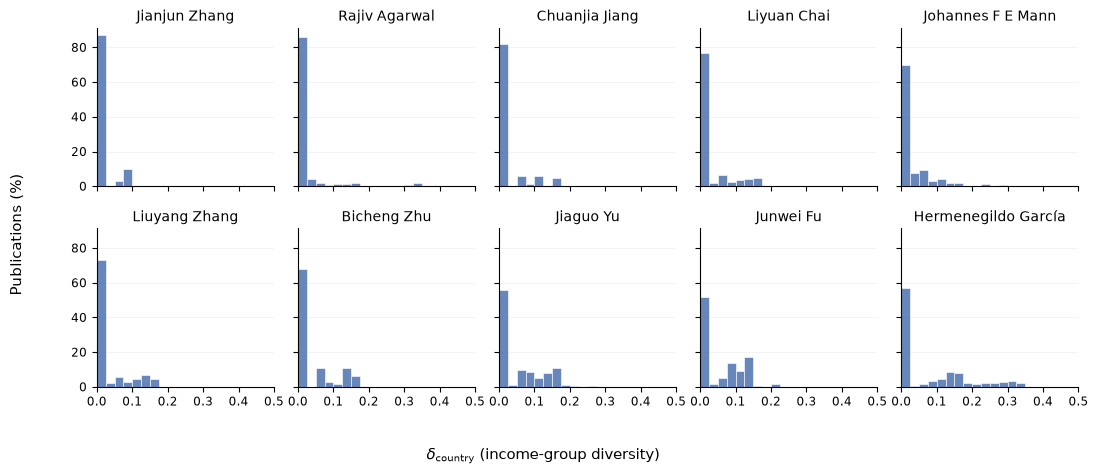

In [23]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make sure output folder exists
os.makedirs("final_figures", exist_ok=True)

# -----------------------------
# Load and merge data
# -----------------------------
paper_scores = pd.read_csv(
    "results_extended/paper_scores.csv",
    index_col="pub_anon_id",
)

extended = pd.read_csv("adapted_extended_cohort.csv")

extended_with_scores = extended.merge(
    paper_scores[["delta_country"]],
    left_on="pub_anon_id",
    right_index=True,
    how="left",
)

seed_name_lookup_anon = dict(
    zip(
        seeds_meta["author_anon_id"],
        seeds_meta["first_name"] + " " + seeds_meta["last_name"],
    )
)
'''
plot_data = extended_with_scores.dropna(
    subset=["seed_author_anon_id", "delta_country"]
).copy()
'''
# replaced the above code with: 
plot_data = (
    extended_with_scores
    .dropna(subset=["seed_author_anon_id", "delta_country"])
    .drop_duplicates(subset=["seed_author_anon_id", "pub_anon_id"])
    .copy()
)
# -----------------------------
# Set up facets
# -----------------------------
# Order seeds by mean country diversity so the visual arc is meaningful
seed_order = (
    plot_data.groupby("seed_author_anon_id")["delta_country"]
    .mean()
    .sort_values()
    .index.tolist()
)

n_cols = 5
n_rows = int(np.ceil(len(seed_order) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(11, 2.4 * n_rows),   # slightly smaller for print
    sharex=True,
    sharey=True,
)

axes = np.atleast_1d(axes).flatten()

bins = np.linspace(0, 0.5, 21)

# -----------------------------
# Plot each seed
# -----------------------------
for ax, seed_id in zip(axes, seed_order):
    values = plot_data.loc[
        plot_data["seed_author_anon_id"] == seed_id,
        "delta_country",
    ]

    weights = np.ones(len(values)) * 100 / len(values)

    ax.hist(
        values,
        bins=bins,
        weights=weights,
        edgecolor="white",
        linewidth=0.5,
        alpha=0.85,
        color="#4C72B0",
    )

    name = seed_name_lookup_anon.get(seed_id, str(seed_id))

    ax.set_title(name, fontsize=10, pad=5)  # kept: identifies panel

    ax.set_xlim(0, 0.5)
    ax.set_ylim(bottom=0)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(axis="y", alpha=0.2, linewidth=0.5)
    ax.set_axisbelow(True)

    ax.tick_params(axis="both", labelsize=8.5)

# Remove unused panels
for ax in axes[len(seed_order):]:
    ax.remove()

# -----------------------------
# Shared labels (no suptitle — goes in caption)
# -----------------------------
fig.supxlabel(
    r"$\delta_{\mathrm{country}}$ (income-group diversity)",
    fontsize=10.5,
    y=0.02,
)

fig.supylabel(
    "Publications (%)",
    fontsize=10.5,
    x=0.015,
)

# NO fig.suptitle() — caption handles it

fig.tight_layout(rect=[0.03, 0.04, 1, 1], h_pad=1.2, w_pad=1.0)

# -----------------------------
# Save
# -----------------------------
fig.savefig("final_figures/fig2_per_seed_histograms.pdf", bbox_inches="tight")
fig.savefig("final_figures/fig2_per_seed_histograms.png", dpi=300, bbox_inches="tight")

plt.show()

In [1]:
paper_zero_rates = (
    plot_data.groupby("seed_author_anon_id")["delta_country"]
    .apply(lambda x: (x == 0).mean() * 100)
    .sort_values(ascending=False)
)

for seed_id, rate in paper_zero_rates.items():
    name = seed_name_lookup_anon.get(seed_id, str(seed_id))
    n_papers = (plot_data["seed_author_anon_id"] == seed_id).sum()
    print(f"  {name}: {rate:.1f}% zero-country ({n_papers} papers)")

NameError: name 'plot_data' is not defined

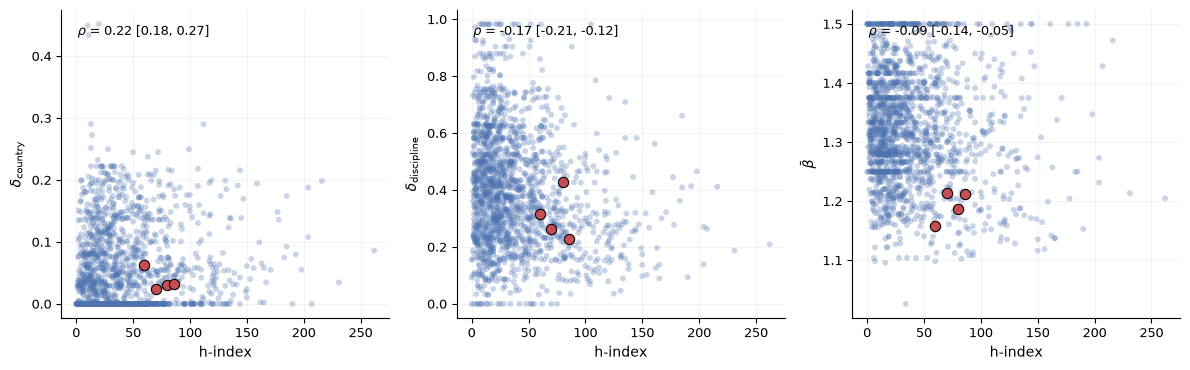


Spearman correlations with h-index (95% CI, Fisher's z):
  delta_country: rho = 0.224 [0.178, 0.268], n = 1684
  delta_discipline: rho = -0.169 [-0.215, -0.122], n = 1684
  beta_mean: rho = -0.093 [-0.140, -0.046], n = 1684
  n_papers: rho = 0.199 [0.152, 0.244], n = 1684


In [26]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs("final_figures", exist_ok=True)


def spearman_with_ci(x, y, alpha=0.05):
    """Spearman rho with Fisher-z 95% CI."""
    valid = ~(np.isnan(x) | np.isnan(y))
    x, y = x[valid], y[valid]
    n = len(x)
    rho, _ = stats.spearmanr(x, y)
    z = np.arctanh(rho)
    se = 1.0 / np.sqrt(n - 3)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    ci_low = np.tanh(z - z_crit * se)
    ci_high = np.tanh(z + z_crit * se)
    return rho, ci_low, ci_high, n


# --------------------------------
# Variables to plot
# --------------------------------
cols = ["delta_country", "delta_discipline", "beta_mean"]

y_labels = [
    r"$\delta_{\mathrm{country}}$",
    r"$\delta_{\mathrm{discipline}}$",
    r"$\bar{\beta}$",
]

# --------------------------------
# Identify seed authors
# --------------------------------
seed_ids = list(seed_name_lookup.keys())

seed_rows = multi[
    multi.index.isin(seed_ids) | multi["author_anon_id"].isin(seed_ids)
].copy()

# --------------------------------
# Create figure
# --------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True)

for ax, col, ylabel in zip(axes, cols, y_labels):

    plot_data = multi[["h_index", col]].dropna()

    # Background: all multi-paper authors
    ax.scatter(
        plot_data["h_index"],
        plot_data[col],
        s=18,
        alpha=0.3,
        color="#4C72B0",
        edgecolors="none",
    )

    # Seeds: red with black outline (no legend, caption explains)
    seed_plot = seed_rows[["h_index", col]].dropna()
    if len(seed_plot):
        ax.scatter(
            seed_plot["h_index"],
            seed_plot[col],
            s=55,
            color="#C44E52",
            edgecolors="black",
            linewidths=0.8,
            zorder=3,
        )

    # Spearman with 95% CI (Fisher z), plain text, no surrounding box
    rho, ci_low, ci_high, n = spearman_with_ci(
        plot_data["h_index"].values, plot_data[col].values
    )
    ax.text(
        0.05,
        0.95,
        rf"$\rho$ = {rho:.2f} [{ci_low:.2f}, {ci_high:.2f}]",
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
    )

    # NO ax.set_title() — panel labels go in caption
    ax.set_xlabel("h-index", fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.tick_params(axis="both", labelsize=9)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(alpha=0.2, linewidth=0.5)
    ax.set_axisbelow(True)

# NO fig.suptitle() — goes in caption
# NO fig.legend() — caption explains the color scheme

fig.tight_layout()

# --------------------------------
# Save
# --------------------------------
fig.savefig("final_figures/fig3_hindex.pdf", bbox_inches="tight")
fig.savefig("final_figures/fig3_hindex.png", dpi=300, bbox_inches="tight")

plt.show()

# --------------------------------
# Print correlations with CI (for reporting in Results)
# --------------------------------
print("\nSpearman correlations with h-index (95% CI, Fisher's z):")
for col in ["delta_country", "delta_discipline", "beta_mean", "n_papers"]:
    plot_data = multi[["h_index", col]].dropna()
    rho, ci_low, ci_high, n = spearman_with_ci(
        plot_data["h_index"].values, plot_data[col].values
    )
    print(f"  {col}: rho = {rho:.3f} [{ci_low:.3f}, {ci_high:.3f}], n = {n}")